# 04 - What can a shadow tell us, when nothing else is noisy?

Notebook 03 found that on KITTI the shadow score barely moved when the depth was scaled,
warped or given a wrong focal length; only a wrong sun direction moved it. Two explanations:

1. **physics** - a sun at infinity makes shadows blind to these errors, or
2. **pipeline** - the dark-asphalt detector and the screen-space renderer are too noisy.

Here the scene is synthetic and exact (`src/synthetic.py`): a road, a wall, a car, a pole
and a building, with true shadows from 3D ray casting. We render shadows from corrupted
depth with the same screen-space renderer as before and score them against the truth.

Expected from theory:
- global scale: exact invariance (a scaled scene casts the same image-space shadows);
- shape warp and wrong focal: should be detectable, because they change the 3D
  offsets between caster and receiver.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import scene
import shadows
import synthetic

FIG = ROOT / "outputs/figures"
H, W = 188, 620
K = np.array([[180.0, 0, 309.5], [0, 180.0, 93.5], [0, 0, 1]])  # KITTI-like field of view at 1/2 size

depth, ground, boxes = synthetic.make_scene(K, H, W)
SUNS = [(-40, 30), (-20, 45), (25, 35), (50, 25)]  # (azimuth, elevation) in degrees

## 1. Does the screen-space renderer reproduce the exact shadows from the true depth?

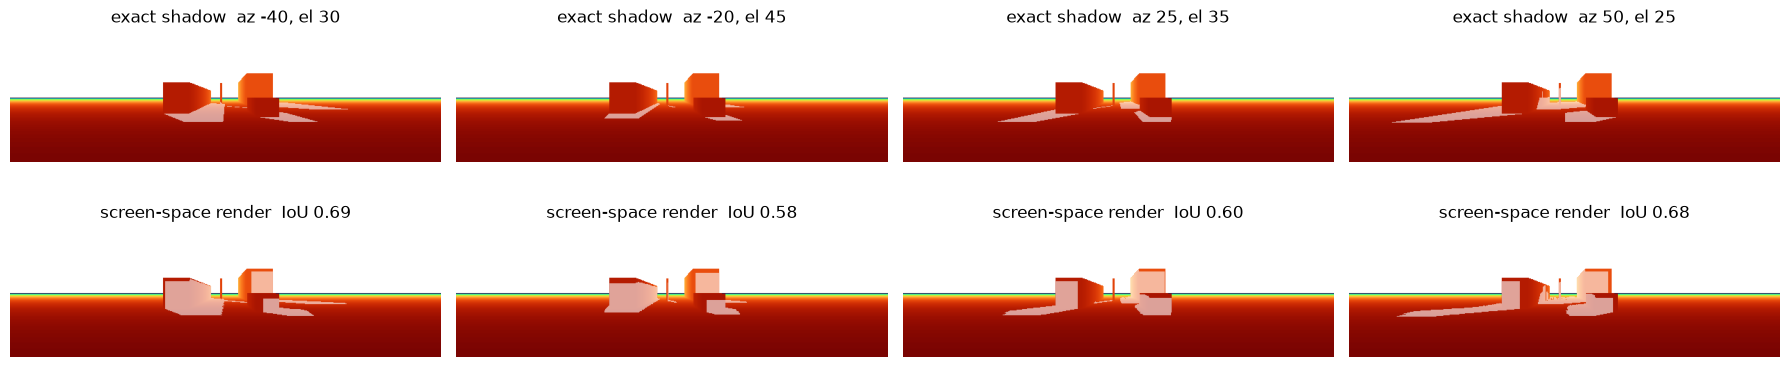

renderer IoU on the ground, true depth: [0.689 0.583 0.598 0.677]


In [2]:
fig, axes = plt.subplots(2, len(SUNS), figsize=(18, 4.5))
renderer_iou = []
for k, (az, el) in enumerate(SUNS):
    s = synthetic.sun_vector(az, el)
    truth = synthetic.exact_shadow(K, H, W, depth, boxes, s)
    rendered = shadows.render_shadow(depth, K, s, max_dist=40.0, n_steps=96)
    renderer_iou.append(scene.iou(rendered, truth, ground))
    axes[0, k].imshow(np.where(depth > 0, depth, np.nan), cmap="turbo_r")
    axes[0, k].imshow(np.ma.masked_where(~truth, truth), cmap="gray_r", alpha=0.6)
    axes[0, k].set_title(f"exact shadow  az {az}, el {el}")
    axes[1, k].imshow(np.where(depth > 0, depth, np.nan), cmap="turbo_r")
    axes[1, k].imshow(np.ma.masked_where(~rendered, rendered), cmap="gray_r", alpha=0.6)
    axes[1, k].set_title(f"screen-space render  IoU {renderer_iou[-1]:.2f}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "04_synthetic_renderer_check.png", dpi=70)
plt.show()
print("renderer IoU on the ground, true depth:", np.round(renderer_iou, 3))

## 2. Corruption study with an exact "detector"
The target is the exact shadow from the true geometry; the rendering uses the corrupted
depth / focal. This is notebook 03 with all detector noise removed.

In [3]:
def warp(d, g):
    m = np.median(d[d > 0])
    out = d.copy()
    out[d > 0] = m * (d[d > 0] / m) ** g
    return out


RENDER = dict(max_dist=40.0, n_steps=96, eps=0.15, thickness=3.0)


def score(fn, tol_scale=1.0):
    """tol_scale multiplies the renderer's metric tolerances (eps, thickness, max_dist)."""
    kw = dict(RENDER, max_dist=RENDER["max_dist"] * tol_scale, eps=RENDER["eps"] * tol_scale,
              thickness=RENDER["thickness"] * tol_scale)
    vals = []
    for az, el in SUNS:
        s = synthetic.sun_vector(az, el)
        truth = synthetic.exact_shadow(K, H, W, depth, boxes, s)
        d, Kc = fn(depth.copy(), K.copy())
        vals.append(scene.iou(shadows.render_shadow(d, Kc, s, **kw), truth, ground))
    return float(np.mean(vals))


def with_focal(Kc, k):
    Kc[0, 0] *= k
    Kc[1, 1] *= k
    return Kc


studies = {
    "global scale s": ([0.5, 0.75, 1.0, 1.5, 2.0], lambda a: (lambda d, Kc: (d * a, Kc))),
    "shape warp gamma": ([0.6, 0.8, 1.0, 1.25, 1.5], lambda g: (lambda d, Kc: (warp(d, g), Kc))),
    "focal factor k": ([0.6, 0.8, 1.0, 1.25, 1.5], lambda k: (lambda d, Kc: (d, with_focal(Kc, k)))),
}
results = {name: (xs, [score(make(x)) for x in xs]) for name, (xs, make) in studies.items()}
# the renderer has three tolerances in metres; scale them with the scene and the
# invariance should become exact, which separates physics from renderer artefacts
xs = studies["global scale s"][0]
results["global scale s, tolerances x s"] = (xs, [score(studies["global scale s"][1](a), tol_scale=a) for a in xs])
for name, (xs, ys) in results.items():
    print(f"{name:18s}", "  ".join(f"{x}:{y:.3f}" for x, y in zip(xs, ys)))

global scale s     0.5:0.546  0.75:0.591  1.0:0.637  1.5:0.681  2.0:0.666
shape warp gamma   0.6:0.533  0.8:0.727  1.0:0.637  1.25:0.499  1.5:0.410
focal factor k     0.6:0.448  0.8:0.700  1.0:0.637  1.25:0.493  1.5:0.420
global scale s, tolerances x s 0.5:0.637  0.75:0.637  1.0:0.637  1.5:0.637  2.0:0.637


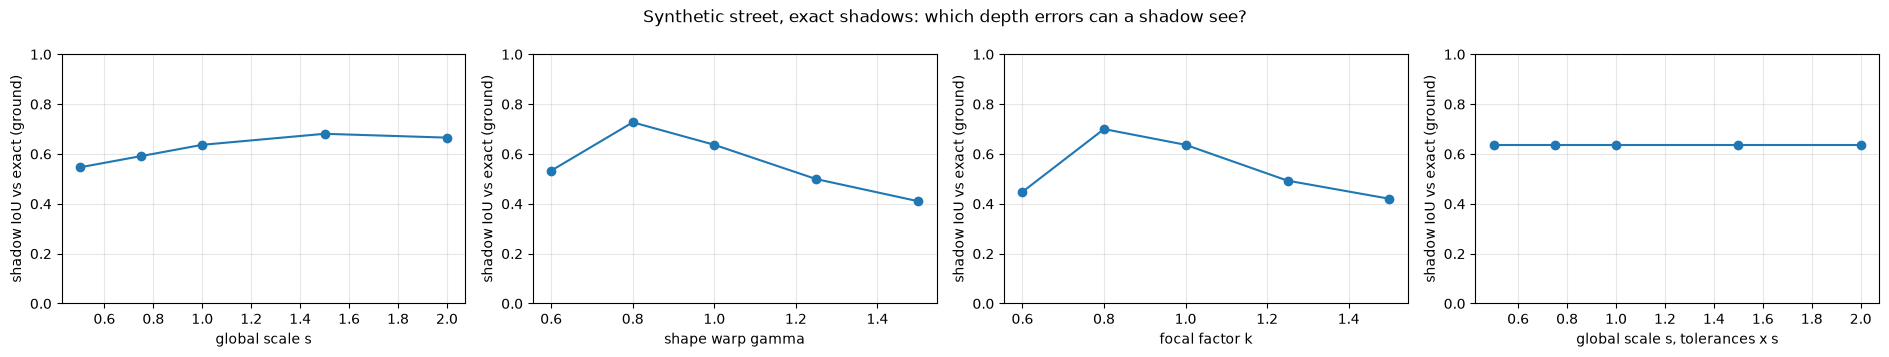

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, (name, (xs, ys)) in zip(axes, results.items()):
    ax.plot(xs, ys, "o-")
    ax.set(xlabel=name, ylabel="shadow IoU vs exact (ground)", ylim=(0, 1))
    ax.grid(alpha=0.3)
plt.suptitle("Synthetic street, exact shadows: which depth errors can a shadow see?")
plt.tight_layout()
plt.savefig(FIG / "04_synthetic_corruptions.png", dpi=80)
plt.show()

## Reading
- With metric tolerances scaled along with the scene, global scale is exactly invariant:
  the small slope in the plain scale curve is a renderer artefact, not physics.
- Shape warp and wrong focal length lower the IoU clearly (about 0.64 -> 0.41-0.45 at
  +-50 %), so in principle a shadow does see relative shape and the camera.
- The curves peak slightly below 1.0: the screen-space renderer misses about 15 % of the exact
  shadow (rays that leave the image, thin casters), and compressed depth, which casts longer
  shadows, partly makes up for it. (An earlier version of this note said the renderer
  over-extends shadows; counting pixels shows the opposite.)
- On real KITTI (notebook 03) all of these were flat around IoU 0.07, so the signal was lost to
  the shadow detector and to off-screen casters, not to the geometry.